# **Test the project files**

<p align="center">
  <img src="diagram.png" alt="Project architecture diagram" width="800" />
</p>


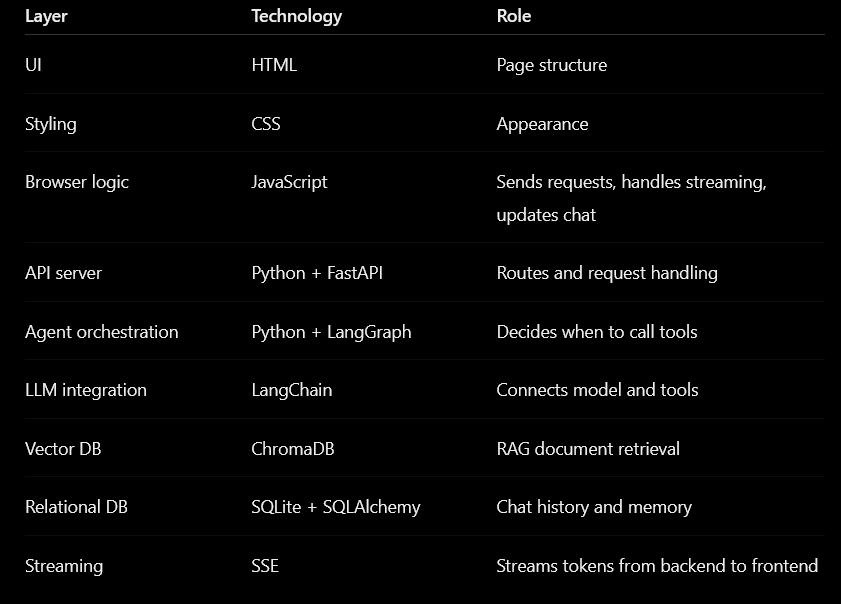

## RAG test

In [ ]:
from pathlib import Path
from typing import List
from dotenv import load_dotenv
import os
import certifi

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

from langchain_chroma import Chroma
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

from pypdf import PdfReader
import docx2txt


Path("uploads").mkdir(exist_ok=True)
Path("chroma_db").mkdir(exist_ok=True)


# Embeddings model
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-large",
    api_key=api_key,
    base_url=base_url,
)

vectorstore = Chroma(
    collection_name="agentic_chatbot_docs",
    embedding_function=embeddings,
    persist_directory="chroma_db"
)

In [13]:
def read_file_text(file_path: str) -> str:
    path = Path(file_path)
    suffix = path.suffix.lower()

    if suffix == ".pdf":
        reader = PdfReader(file_path)
        text = ""

        for page in reader.pages:
            text += page.extract_text() or ""
            text += "\n"

        return text

    if suffix == ".docx":
        return docx2txt.process(file_path)

    if suffix in [".txt", ".md", ".py", ".csv"]:
        return path.read_text(encoding="utf-8", errors="ignore")

    raise ValueError("Unsupported file type. Upload PDF, DOCX, TXT, MD, PY, or CSV.")


file_path_pdf = r"C:\Users\meisa\Desktop\Code\ML\Agent_AI\Youtube\Agent_deployment\ChromaDB_Chatbot\CV.pdf"
file_path_py = r"C:\Users\meisa\Desktop\Code\ML\Agent_AI\Youtube\Agent_deployment\ChromaDB_Chatbot\tools.py"
thread_id = "test_thread_1"

# 1. Test file reading
text1 = read_file_text(file_path_pdf)

print("=== Extracted text ===")
print(text1[:100])   # only first 1000 characters


# 2. Test file reading python
text2 = read_file_text(file_path_py)

print("\n=== Extracted text ===")
print(text2[:100])   # only first 1000 characters

=== Extracted text ===
Meisam Ghasemi Bostanabad
Machine Learning Engineer | Data Scientist | Applied ML Researcher
mghasem

=== Extracted text ===
import math
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_tavi


In [ ]:
def add_document_to_rag(file_path: str, thread_id: str):
    text = read_file_text(file_path)

    if not text.strip():
        raise ValueError("No text could be extracted from this file.")

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=900,
        chunk_overlap=150
    )

    chunks = splitter.split_text(text)

    docs: List[Document] = [
        Document(
            page_content=chunk,
            metadata={
                "thread_id": thread_id,
                "source": Path(file_path).name
            }
        )
        for chunk in chunks
    ]

    vectorstore.add_documents(docs)

    return {
        "filename": Path(file_path).name,
        "chunks": len(docs)
    }




# 2. Test adding document to ChromaDB
result = add_document_to_rag(
    file_path=file_path_pdf,
    thread_id=thread_id
)

print("\n=== Add document result ===")
print(result)



=== Add document result ===
{'filename': 'CV.pdf', 'chunks': 11}


In [ ]:
def retrieve_from_rag(query: str, thread_id: str, k: int = 4) -> str:
    docs = vectorstore.similarity_search(
        query,
        k=k,
        filter={"thread_id": thread_id}
    )

    if not docs:
        return "No relevant uploaded document content found."

    results = []

    for i, doc in enumerate(docs, start=1):
        source = doc.metadata.get("source", "uploaded document")
        results.append(
            f"[Source {i}: {source}]\n{doc.page_content}"
        )

    return "\n\n".join(results)



# 3. Test retrieval
query = "What is this document about?"

answer = retrieve_from_rag(
    query=query,
    thread_id=thread_id,
    k=4
)

print("\n=== Retrieved chunks ===")
print(answer)


=== Retrieved chunks ===
[Source 1: CV.pdf]
• Developed anomaly-detection models for dynamic-aperture simulations using particle-tracking data.
• Fine-tuned Qwen 3.8B with QLoRA on HEP papers and code, then developed a RAG-based AI agent for expert-level
question answering in particle physics.
GOODFOLIO / SEPANTA Remote
LLM Engineer Oct. 2024 - Aug. 2025
• Fine-tuned Qwen language model on domain-specific enterprise data using QLORA technique to improve task
accuracy, terminology understanding, and structured response generation.
• Designed data pipelines for collecting, cleaning, anonymising, validating, and formatting real-world documents,
user interactions, and human-reviewed examples into versioned training and evaluation datasets.
• Developed a domain-aware AI chatbot combining fine-tuned models, retrieval-augmented generation, conversation

[Source 2: CV.pdf]
• Links: GitHub | Publication
Rare Exotic Event Detection with Deep Learning Python, PyTorch, Statistical Inference
• Dev

## SQLAlchemy DB test

In [16]:
from datetime import datetime
from pathlib import Path

from sqlalchemy import create_engine, Column, Integer, String, Text, DateTime
from sqlalchemy.orm import declarative_base, sessionmaker

Path("data").mkdir(exist_ok=True)

DATABASE_URL = "sqlite:///data/chatbot_memory.db"

engine = create_engine(
    DATABASE_URL,
    connect_args={"check_same_thread": False}
)

SessionLocal = sessionmaker(bind=engine, autoflush=False, autocommit=False)
Base = declarative_base()


class Conversation(Base):
    __tablename__ = "conversations"

    id = Column(Integer, primary_key=True, index=True)
    thread_id = Column(String, unique=True, index=True)
    title = Column(String, default="New Chat")
    created_at = Column(DateTime, default=datetime.utcnow)
    updated_at = Column(DateTime, default=datetime.utcnow)


class ChatMessage(Base):
    __tablename__ = "chat_messages"

    id = Column(Integer, primary_key=True, index=True)
    thread_id = Column(String, index=True)
    role = Column(String)
    content = Column(Text)
    created_at = Column(DateTime, default=datetime.utcnow)


class LongTermMemory(Base):
    __tablename__ = "long_term_memory"

    id = Column(Integer, primary_key=True, index=True)
    thread_id = Column(String, index=True)
    memory = Column(Text)
    created_at = Column(DateTime, default=datetime.utcnow)


def init_db():
    Base.metadata.create_all(bind=engine)


def create_or_update_conversation(thread_id: str, first_message: str | None = None):
    db = SessionLocal()

    try:
        conversation = (
            db.query(Conversation)
            .filter(Conversation.thread_id == thread_id)
            .first()
        )

        if not conversation:
            title = "New Chat"

            if first_message:
                title = first_message.strip()[:40]
                if len(first_message.strip()) > 40:
                    title += "..."

            conversation = Conversation(
                thread_id=thread_id,
                title=title,
                created_at=datetime.utcnow(),
                updated_at=datetime.utcnow()
            )

            db.add(conversation)

        else:
            conversation.updated_at = datetime.utcnow()

        db.commit()

    finally:
        db.close()


def list_conversations():
    db = SessionLocal()

    try:
        return (
            db.query(Conversation)
            .order_by(Conversation.updated_at.desc())
            .all()
        )

    finally:
        db.close()


def save_chat_message(thread_id: str, role: str, content: str):
    db = SessionLocal()

    try:
        msg = ChatMessage(
            thread_id=thread_id,
            role=role,
            content=content,
            created_at=datetime.utcnow()
        )

        db.add(msg)

        conversation = (
            db.query(Conversation)
            .filter(Conversation.thread_id == thread_id)
            .first()
        )

        if conversation:
            conversation.updated_at = datetime.utcnow()

        db.commit()

    finally:
        db.close()


def get_chat_history(thread_id: str):
    db = SessionLocal()

    try:
        return (
            db.query(ChatMessage)
            .filter(ChatMessage.thread_id == thread_id)
            .order_by(ChatMessage.created_at.asc())
            .all()
        )

    finally:
        db.close()


def save_memory(thread_id: str, memory: str):
    db = SessionLocal()

    try:
        item = LongTermMemory(
            thread_id=thread_id,
            memory=memory,
            created_at=datetime.utcnow()
        )

        db.add(item)
        db.commit()

        return "Memory saved successfully."

    finally:
        db.close()


def search_memory(thread_id: str, query: str):
    db = SessionLocal()

    try:
        memories = (
            db.query(LongTermMemory)
            .filter(LongTermMemory.thread_id == thread_id)
            .order_by(LongTermMemory.created_at.desc())
            .limit(20)
            .all()
        )

        if not memories:
            return "No saved memory found."

        return "\n".join([f"- {m.memory}" for m in memories])

    finally:
        db.close()

In [20]:
for msg in get_chat_history("ad1c095b-46ea-4e98-8582-74ed12026f3c"):
    print(msg.id, msg.role, msg.content, msg.created_at)

1 user Hi I am Bappy 2026-06-23 06:54:21.905823
2 user Hi I am Bappy 2026-06-23 06:54:40.405920
3 assistant Hi Bappy! It's nice to meet you. How can I help you today? 2026-06-23 06:54:42.072407


In [25]:
search_memory("14e509fd-5c27-4382-bf41-d9be28c1ae41", "memory")

'- My name is Alex'

In [28]:
for msg in list_conversations():
    print(msg.id, msg.thread_id, msg.title)

4 9c36da05-7d95-4c15-a904-40fc31d10a1a Hi I am Meisam and I am 35 years old. Wh...
3 ab43277e-be24-4806-83e2-34fd3364b0c9 My favorite colors is red
2 14e509fd-5c27-4382-bf41-d9be28c1ae41 My name Alex
1 ad1c095b-46ea-4e98-8582-74ed12026f3c Hi I am Bappy


## Agent test

In [5]:
import os
import sqlite3
from pathlib import Path

from dotenv import load_dotenv
import certifi

load_dotenv()
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")


os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.sqlite import SqliteSaver
from tools import tools

Path("data").mkdir(exist_ok=True)


# Update default and allowed models to use Gemini 2.5
DEFAULT_MODEL = os.getenv("GEMINI_MODEL", "gemini-2.5-flash")

ALLOWED_MODELS = {
    "gemini-2.5-flash",
    "gemini-2.5-pro",
    "gemini-2.5-flash-lite", # Included the lite version if needed
    "gemini-1.5-flash",      # Kept for fallback compatibility 
    "gemini-1.5-pro"
}



SYSTEM_PROMPT = """
                You are a helpful Agentic AI assistant named MeisamGPT similar to ChatGPT.

                You can:
                1. Answer normal questions.
                2. Use tools when needed.
                3. Search uploaded documents using the RAG tool.
                4. Search the web for latest/current information using Tavily Search.
                5. Remember important user information using the memory tool.
                6. Recall memory when useful.
                7. Use calculator for math.

                Rules:
                - If the user asks about latest news, current events, recent updates, today's information, current prices, current people, current versions, new releases, or anything time-sensitive, 
                  use Tavily Search.
                - If the user asks about an uploaded document, use search_uploaded_documents.
                - If the user asks you to remember something, use remember_this.
                - If the user asks about previous preferences or saved facts, use recall_memory.
                - Use calculator for math questions.
                - When using web search, summarize clearly and mention that the answer is based on web search results.
                - Be clear, helpful, and concise.
                """



def normalize_model_name(model_name: str | None) -> str:
    """
    Validate selected model from frontend.
    If model is missing or not allowed, fallback to DEFAULT_MODEL.
    """

    if not model_name:
        return DEFAULT_MODEL

    model_name = model_name.strip()

    if model_name not in ALLOWED_MODELS:
        return DEFAULT_MODEL

    return model_name




def build_agent(model_name: str):
    """
    Build one LangGraph agent for a selected Gemini model.
    """

    selected_model = normalize_model_name(model_name)

    # Initialize ChatOpenAI
    llm = ChatOpenAI(
        model=selected_model,
        temperature=0.3,
        streaming=True,
        openai_api_key=api_key,
        base_url=base_url
    )

    llm_with_tools = llm.bind_tools(tools)

    def chatbot_node(state: MessagesState):
        messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]

        response = llm_with_tools.invoke(messages)

        return {
            "messages": [response]
        }

    tool_node = ToolNode(tools)

    workflow = StateGraph(MessagesState)

    workflow.add_node("chatbot", chatbot_node)
    workflow.add_node("tools", tool_node)

    workflow.add_edge(START, "chatbot")
    workflow.add_conditional_edges("chatbot", tools_condition)
    workflow.add_edge("tools", "chatbot")

    conn = sqlite3.connect(
        "data/langgraph_checkpoints.sqlite",
        check_same_thread=False
    )

    checkpointer = SqliteSaver(conn)

    return workflow.compile(checkpointer=checkpointer)


_AGENT_CACHE = {}


def get_agent(model_name: str | None = None):
    """
    Return cached LangGraph agent for selected model.
    If not created yet, create it once and reuse it.
    """

    selected_model = normalize_model_name(model_name)

    if selected_model not in _AGENT_CACHE:
        _AGENT_CACHE[selected_model] = build_agent(selected_model)

    return _AGENT_CACHE[selected_model]

## App test

```text 
Frontend
HTML + CSS + JavaScript
        ↓ HTTP / fetch / SSE
Backend
Python + FastAPI
        ↓
Agent
Python + LangChain + LangGraph
        ↓
Tools / RAG / Memory / Web Search / Calculator
```

# Full Flow Walkthrough with a Concrete Example

Let's trace a real user message through the entire system, step by step.

**Example scenario:** The user types **"What's the weather in Berlin?"** in their browser.

---

## Step 0: The Setup (Before Any Request)

Before the user even types, several things are already in place:

```
Browser                          FastAPI                          SQLite
   │                                │                                │
   │                                │  Server running on :8080       │
   │                                │  init_db() already called      │
   │                                │  Tables created:               │
   │                                │    - conversations             │
   │                                │    - chat_messages             │
   │                                │    - long_term_memory          │
   │                                │                                │
   │  GET / (page loads)            │                                │
   ├───────────────────────────────►│                                │
   │◄───────────────────────────────┤                                │
   │  HTML + CSS + JS rendered      │                                │
   │                                │                                │
   │  GET /conversations            │                                │
   ├───────────────────────────────►│  SELECT * FROM conversations ─►│
   │◄───────────────────────────────┤◄───────────────────────────────┤
   │  Sidebar populated             │                                │
```

State at this point:
- Browser has a `threadId` (from `localStorage`, e.g., `"ad1c095b-46ea-4e98-8582-74ed12026f3c"`)
- The input box is focused and ready

---

## Step 1: User Types and Presses Enter

```
Browser
   │
   │  User types: "What's the weather in Berlin?"
   │  Presses Enter (or clicks ➜)
   │
   │  JS: sendMessage() runs
   │     ├── addMessage("user", "What's the weather in Berlin?")
   │     ├── Detects tool: "Web Search" (matches /weather|current|.../)
   │     ├── addToolProgress("Web Search")  ← spinner appears
   │     └── fetch POST /chat/stream
   │           body: { message: "What's the weather in Berlin?",
   │                   thread_id: "ad1c095b-...",
   │                   model: "gemini-2.5-flash" }
```

The browser now shows:
- User bubble with the message
- A spinner: "🔄 Using Web Search..."
- Status bar: "Using Web Search..."

---

## Step 2: FastAPI Receives the Request

```
Browser                          FastAPI
   │                                │
   │  POST /chat/stream             │
   │  {message, thread_id, model}   │
   ├───────────────────────────────►│
   │                                │
   │                                │  data = await request.json()
   │                                │  user_message = "What's the weather in Berlin?"
   │                                │  thread_id = "ad1c095b-..."
   │                                │  selected_model = "gemini-2.5-flash"
   │                                │
   │                                │  Validation ✓ (non-empty)
   │                                │
   │                                │  agent = get_agent("gemini-2.5-flash")
   │                                │    └── LangGraph graph compiled with
   │                                │        the Gemini model + tools
```

At this point, FastAPI has:
- Validated the input
- Built/retrieved the LangGraph agent
- **Not yet** started streaming

---

## Step 3: Save the User's Message FIRST

```
Browser                          FastAPI                          SQLite
   │                                │                                │
   │                                │  create_or_update_conversation(│
   │                                │    "ad1c095b-...",             │
   │                                │    "What's the weather...")    │
   │                                ├───────────────────────────────►│
   │                                │  UPSERT conversations          │
   │                                │    thread_id = "ad1c095b-..."  │
   │                                │    title     = "What's the wea…"│
   │                                │    updated_at = now()          │
   │                                │◄───────────────────────────────┤
   │                                │                                │
   │                                │  save_chat_message(            │
   │                                │    "ad1c095b-...",             │
   │                                │    "user",                     │
   │                                │    "What's the weather...")    │
   │                                ├───────────────────────────────►│
   │                                │  INSERT INTO chat_messages     │
   │                                │◄───────────────────────────────┤
   │                                │                                │
   │                                │  set_current_thread_id(...)    │
   │                                │  (context var for tools)       │
```

**Why do this before streaming?** If the LLM crashes, the user's message is still persisted. The conversation isn't lost.

The `conversations` table now has:
```
| id | thread_id (uuid) | title                  | updated_at |
| 1  | ad1c095b-...     | "What's the weather ..."| 2026-10-15 |
```

The `chat_messages` table now has:
```
| id | thread_id    | role | content                       | created_at |
| 1  | ad1c095b-... | user | "What's the weather in Berlin?"| 2026-10-15 |
```

---

## Step 4: Start the SSE Stream — Run the Agent

```
Browser                          FastAPI                          LangGraph
   │                                │                                │
   │                                │  return StreamingResponse(     │
   │                                │    event_generator(),          │
   │                                │    media_type="text/event-stream"
   │                                │  )                             │
   │                                │                                │
   │  ◄─── (headers sent) ──────────┤                                │
   │  HTTP 200                      │                                │
   │  Content-Type: text/event-stream                                │
   │  X-Accel-Buffering: no         │                                │
   │                                │                                │
   │  (connection stays open)       │  event_generator() starts:     │
   │                                │    agent.stream(               │
   │                                │      {"messages": [            │
   │                                │        HumanMessage(...)       │
   │                                │      ]},                       │
   │                                │      config={                  │
   │                                │        "configurable": {       │
   │                                │          "thread_id": "ad1c..."│
   │                                │        }                       │
   │                                │      },                        │
   │                                │      stream_mode="messages"    │
   │                                │    )                           │
   │                                ├───────────────────────────────►│
   │                                │                                │
   │                                │                                │  Graph loads state
   │                                │                                │  from checkpointer
   │                                │                                │  for thread_id
   │                                │                                │  (SQLite via SqliteSaver)
   │                                │                                │
   │                                │                                │  Node 1: chat_node
   │                                │                                │    LLM decides to call
   │                                │                                │    get_current_weather
   │                                │                                │    tool
   │                                │                                │
   │                                │                                │  Node 2: tools
   │                                │                                │    Calls OpenWeather API
   │                                │                                │    for "Berlin"
   │                                │                                │    Returns result
   │                                │                                │
   │                                │                                │  Node 3: chat_node (again)
   │                                │                                │    LLM generates final
   │                                │                                │    answer using the
   │                                │                                │    weather data
```

**Important detail:** The agent runs multiple nodes internally. `should_stream_chunk` filters out everything except the final AI answer — so the browser never sees the tool call, the tool result, or the intermediate LLM reasoning.

---

## Step 5: Stream the First Token

LangGraph starts emitting tokens. Here's the first one:

```
Browser                          FastAPI                          LangGraph
   │                                │                                │
   │                                │  for chunk, metadata in        │
   │                                │    agent.stream(...):          │
   │                                │                                │
   │                                │  chunk = AIMessageChunk(       │
   │                                │    content="The"               │
   │                                │  )                             │
   │                                │◄───────────────────────────────┤
   │                                │                                │
   │                                │  should_stream_chunk(          │
   │                                │    chunk, metadata)            │
   │                                │    → True (it's AIMessage,     │
   │                                │      no tool_calls)            │
   │                                │                                │
   │                                │  token = extract_text_from_    │
   │                                │    chunk(chunk)                │
   │                                │    → "The"                     │
   │                                │                                │
   │                                │  final_answer += "The"         │
   │                                │                                │
   │                                │  yield sse_data({              │
   │                                │    "token": "The"              │
   │                                │  })                            │
   │                                │                                │
   │  data: {"token": "The"}\n\n    │                                │
   │◄───────────────────────────────┤                                │
   │                                │                                │
   │  JS: handleStreamData({"token":"The"})                          │
   │     ├── firstTokenReceived = true                               │
   │     ├── completeToolProgress("Web Search")  ← spinner → ✓       │
   │     ├── statusText = "Generating with gemini-2.5-flash..."      │
   │     └── botElement.textContent += "The"                         │
```

Browser now shows:
```
[User]: What's the weather in Berlin?

[AI]:   The|
        ↑ blinking cursor
```

Status bar: **"Generating with gemini-2.5-flash..."**
Tool chip: **"✓ Web Search completed"**

---

## Step 6: Stream More Tokens

This repeats for each token:

```
Browser                          FastAPI                          LangGraph
   │                                │                                │
   │  data: {"token": " cap"}\n\n   │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": "ital"}\n\n   │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": " of"}\n\n    │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": " Ger"}\n\n   │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": "many"}\n\n   │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": " is"}\n\n    │◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  data: {"token": " Berlin"}\n\n│◄──── chunk ────────────────────┤
   │◄───────────────────────────────┤                                │
   │  ... (more tokens)             │                                │
```

Each `yield` in FastAPI's `event_generator` flushes immediately to the browser (thanks to `X-Accel-Buffering: no`).

Browser now shows:
```
[AI]: The capital of Germany is Berlin...|
```

Tokens appear one by one — this is the "typewriter effect."

---

## Step 7: Stream Ends, Save the Assistant's Answer

```
Browser                          FastAPI                          SQLite
   │                                │                                │
   │                                │  (stream exhausted)            │
   │                                │                                │
   │                                │  final_answer = "The capital  │
   │                                │  of Germany is Berlin..."      │
   │                                │                                │
   │                                │  save_chat_message(            │
   │                                │    "ad1c095b-...",             │
   │                                │    "assistant",                │
   │                                │    final_answer)               │
   │                                ├───────────────────────────────►│
   │                                │  INSERT INTO chat_messages     │
   │                                │◄───────────────────────────────┤
   │                                │                                │
   │                                │  yield sse_data({              │
   │                                │    "done": True                │
   │                                │  })                            │
   │                                │                                │
   │  data: {"done": true}\n\n      │                                │
   │◄───────────────────────────────┤                                │
   │                                │                                │
   │  (FastAPI closes the stream)   │                                │
```

The `chat_messages` table now has:
```
| id | thread_id    | role      | content                                    |
| 1  | ad1c095b-... | user      | "What's the weather in Berlin?"            |
| 2  | ad1c095b-... | assistant | "The capital of Germany is Berlin..."      |
```

---

## Step 8: Browser Finishes Up

```javascript
// In handleStreamData:
if (data.done) {
    statusText.textContent = "Ready";
}
```

```javascript
// In sendMessage's finally block:
sendBtn.disabled = false;
statusText.textContent = "Ready";
messageInput.focus();
await loadConversations();  // ← sidebar refresh
```

Browser now shows:
```
[User]: What's the weather in Berlin?

[AI]:   The capital of Germany is Berlin...
```

Status: **"Ready"**

Sidebar: **"What's the weather ..."** appears in the recent chats list.

---

## Step 9: User Reloads the Page (Persistence Test)

Later, the user closes the tab and reopens the app:

```
Browser                          FastAPI                          SQLite
   │                                │                                │
   │  GET /                         │                                │
   ├───────────────────────────────►│                                │
   │◄───────────────────────────────┤                                │
   │                                │                                │
   │  JS: threadId = localStorage   │                                │
   │  → "ad1c095b-..."              │                                │
   │                                │                                │
   │  GET /history/ad1c095b-...     │                                │
   ├───────────────────────────────►│  SELECT * FROM chat_messages   │
   │                                │  WHERE thread_id = 'ad1c095b'  │
   │                                │  ORDER BY created_at ASC       │
   │                                ├───────────────────────────────►│
   │                                │◄───────────────────────────────┤
   │◄───────────────────────────────┤                                │
   │  [{role:"user",content:"..."}, │                                │
   │   {role:"assistant",content:"..."}]                            │
   │                                │                                │
   │  JS: renders both messages     │                                │
```

**Both messages reappear** — the conversation survived a full page reload.

---

## Full Timeline Summary

| Time | Event | Where data lives |
|------|-------|------------------|
| T0 | User types message | Browser memory only |
| T1 | User presses Enter | Browser starts fetch |
| T2 | FastAPI parses request | FastAPI memory |
| T3 | User message saved | **SQLite `chat_messages`** |
| T4 | Agent starts, calls weather tool | LangGraph state (checkpointer) |
| T5 | First token streamed | Browser displays partial text |
| T6 | More tokens streamed | Browser text grows |
| T7 | Stream ends | — |
| T8 | Assistant message saved | **SQLite `chat_messages`** |
| T9 | `{"done": true}` sent | Browser resets status |
| T10 | Sidebar refreshed | Browser updates thread list |
| T11 | User reloads page | Fetches from **SQLite `chat_messages`** |

---

## Two Persistence Layers (Don't Confuse Them)

Notice there are **two** places state is saved:

### Layer 1: SQLite `chat_messages` (via SQLAlchemy)
- **Purpose:** UI display + thread listing
- **Written by:** `save_chat_message` in FastAPI
- **Read by:** `/history/{thread_id}` in FastAPI
- **Contains:** Clean role/content pairs

### Layer 2: LangGraph checkpointer (also SQLite, but different file)
- **Purpose:** Agent's memory (full message objects with tool calls, metadata)
- **Written by:** LangGraph automatically during `agent.stream(...)`
- **Read by:** LangGraph automatically when you call `agent.stream` with the same `thread_id`
- **Contains:** Everything — HumanMessage, AIMessage, ToolMessage, tool_calls, etc.

**Why both?** The agent needs full fidelity (tool calls, function args) to reason correctly. The UI just needs clean text. So the code maintains:
- **Agent memory** → LangGraph checkpointer (`new_chatbot.db`)
- **UI history** → SQLAlchemy tables (`data/chatbot_memory.db`)

---

## What Would Break Without Each Piece

| Remove... | What breaks |
|-----------|-------------|
| `save_chat_message(user)` | User messages don't persist; sidebar shows threads with no history |
| `save_chat_message(assistant)` | Answers vanish on reload; checkpointer still has them, but UI is empty |
| `should_stream_chunk` filter | Tool JSON, raw search results, and user echo appear in the chat |
| `X-Accel-Buffering: no` | Render/Nginx buffers the whole response → no typewriter effect |
| `thread_id` in config | Every request starts fresh — no memory |
| `create_or_update_conversation` | Sidebar stays empty — no titles to display |
| `StreamingResponse` | Response only arrives after the full LLM reply is ready |

---

## TL;DR

> The flow is: **(1)** browser POSTs the message → **(2)** FastAPI saves the user message to SQLite → **(3)** FastAPI starts an SSE stream by running the LangGraph agent → **(4)** LangGraph internally runs nodes (chat → tool → chat) and emits tokens → **(5)** FastAPI filters each token and yields SSE events → **(6)** the browser appends each token to the chat bubble in real time → **(7)** when streaming ends, FastAPI saves the final assistant answer to SQLite → **(8)** sends `{"done": true}` → **(9)** the browser refreshes the sidebar. Two separate persistence layers keep the **agent's full memory** (checkpointer) and the **UI's clean history** (SQLAlchemy) in sync.